# 01 · Corpus packing: from recordings to an `.elkgrain` pack

Latent granular synthesis replaces each ≈93 ms frame of a live input with a recorded grain chosen by similarity in
the latent space of a neural audio codec. The desktop instrument (`latent/granular.py`) encodes both the corpus and
the live input with the music2latent encoder, samples a corpus grain for every input frame from a softmax over
cosine similarities with temperature τ, and decodes the result.

The Elk Stomp Dev Kit cannot run that encoder. But the corpus does not change during a performance, so its latents
can be computed offline, on a computer, and stored with the grains' audio in a single memory-mappable file, the
**pack** (`corpus_builder/`, byte-exact format in `docs/pack-format.md`). On the board only the live input still
needs an encoder: that is the student of notebook 02.

This notebook builds a pack from a generated demo corpus (no recording is distributed with this repository), reads
it back, and checks that selection over the pack is the desktop instrument's selection. It ends with the numbers
of the paper it reproduces.

In [1]:
import json, platform, time
from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt

from analysis import demo, report
from analysis.board_logs import load_runs
from corpus_builder import build_corpus, elkgrain, match
from latent import granular

print("python", platform.python_version(), "| torch", version("torch"), "| music2latent", version("music2latent"),
      "| numpy", np.__version__, "|", platform.system(), platform.machine())

python 3.12.8 | torch 2.13.0 | music2latent 0.1.8 | numpy 2.5.2 | Darwin arm64


## 1. A demo corpus

Three 20 s signals, one per character of the paper's corpora (percussive, tonal, textural), generated with fixed
seeds by `analysis/demo.py` and written to `$LBD_WORK/demo/corpus` (git-ignored).

perc.wav    20.0 s at 44100 Hz
text.wav    20.0 s at 44100 Hz
tonal.wav   20.0 s at 44100 Hz


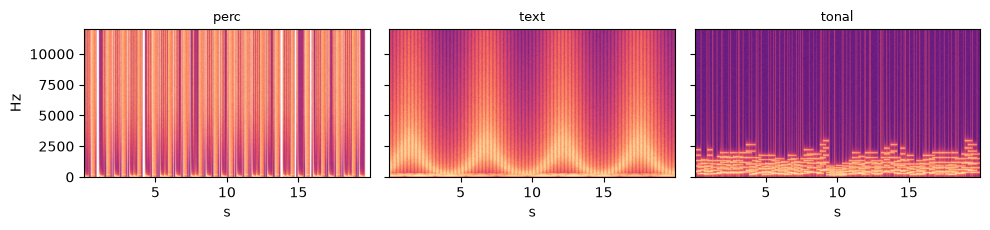

In [2]:
corpus_dir = demo.write_corpus()
files = build_corpus.find_audio(corpus_dir)
y44s = [granular.load_mono_44k(str(p)) for p in files]            # mono, 44.1 kHz, peak-normalised (the instrument's loader)
for p, y in zip(files, y44s):
    print(f"{p.name:10s} {len(y) / granular.CODEC_SR:5.1f} s at {granular.CODEC_SR} Hz")

fig, axes = plt.subplots(1, 3, figsize=(10, 2.4), sharey=True)
for ax, p, y in zip(axes, files, y44s):
    with np.errstate(divide="ignore"):                      # the silent gap has zero power
        ax.specgram(y, NFFT=2048, Fs=granular.CODEC_SR, noverlap=1536, cmap="magma")
    ax.set_title(p.stem, fontsize=9); ax.set_xlabel("s"); ax.set_ylim(0, 12000)
axes[0].set_ylabel("Hz")
fig.tight_layout()

## 2. The music2latent encoder, and why the corpus is encoded offline

music2latent (Pasini et al., 2024) encodes 44.1 kHz audio into 64-dimensional latents at about 10.8 frames per
second and decodes them with a consistency model. Its weights (CC BY-NC 4.0) are downloaded by the `music2latent`
package on first use.

In [3]:
codec = demo.codec()                                   # latent.granular.Codec on the CPU
model = codec.encdec.gen
n_total = sum(p.numel() for p in model.parameters())
parts = {name: sum(p.numel() for p in child.parameters()) for name, child in model.named_children()}
print(f"music2latent parameters: {n_total:,} ({n_total / 1e6:.1f} M)")
print(f"  encoder {parts['encoder']:,} | decoder {parts['decoder']:,} | "
      f"consistency-model layers and the rest {n_total - parts['encoder'] - parts['decoder']:,}")

Model was downloaded successfully!


music2latent parameters: 58,185,026 (58.2 M)
  encoder 16,261,568 | decoder 17,286,464 | consistency-model layers and the rest 24,636,994


In [4]:
lats, times = [], []
for y in y44s:
    t0 = time.perf_counter()
    lat = np.asarray(codec.encode(y), dtype=np.float32)       # [64, T]
    times.append(time.perf_counter() - t0)
    lats.append(lat)
for p, y, lat, dt in zip(files, y44s, lats, times):
    T = lat.shape[1]
    hop = len(y) / T                                           # the codec's effective hop for this file
    print(f"{p.name:10s} latents {lat.shape}  {T / (len(y) / granular.CODEC_SR):5.2f} frames/s  "
          f"hop {hop:6.1f} samples = {1000 * hop / granular.CODEC_SR:5.1f} ms  "
          f"encode {1000 * dt:6.1f} ms on this CPU = {1000 * dt / T:5.2f} ms per frame")

perc.wav   latents (64, 214)  10.70 frames/s  hop 4121.5 samples =  93.5 ms  encode 5814.7 ms on this CPU = 27.17 ms per frame
text.wav   latents (64, 214)  10.70 frames/s  hop 4121.5 samples =  93.5 ms  encode 4459.9 ms on this CPU = 20.84 ms per frame
tonal.wav  latents (64, 214)  10.70 frames/s  hop 4121.5 samples =  93.5 ms  encode 3694.5 ms on this CPU = 17.26 ms per frame


A laptop CPU encodes a frame in milliseconds, which is why the desktop instrument can encode its live input. The Elk
Stomp has two 800 MHz Cortex-A7 cores, no neural processing unit and a 64-sample audio callback (1.333 ms at 48 kHz),
and LibTorch has no official 32-bit armv7 build. The corpus side is therefore encoded here, once, and stored.

## 3. From latents to grains

With `unit = 1` a grain is one latent frame (≈93 ms of audio). `granular.build_codebook` stacks the grains of all
files, drops near-silent ones (−50 dBFS gate on each frame's RMS), and keeps two tables: the raw latents and the
**matching table**, whose rows are mean-centred and L2-normalised, so that a dot product is the mean-centred cosine
the instrument selects by.

In [5]:
cb = granular.build_codebook(lats, unit=1, stride=1, audio_list=y44s, silence_db=-50.0)
print(f"{cb.n} grains, {cb.dropped_silent} near-silent frames dropped")
print("matching-table row norms:", np.round(np.linalg.norm(cb.book, axis=1)[[0, 1, -1]], 6))
print("centre = mean of the raw grains:", np.allclose(cb.centre, cb.raw.mean(0)))

633 grains, 9 near-silent frames dropped
matching-table row norms: [1. 1. 1.]
centre = mean of the raw grains: True


## 4. Writing and reading the pack

`build_corpus.build_pack` runs the same steps through the desktop instrument's own code (so the tables are
bit-identical to what the instrument builds), resamples each file to the board's 48 kHz, stores 16-bit audio for
every grain with 10 ms crossfade margins (overlapping windows share one region of audio), and writes one file.

In [6]:
demo.PACK.unlink(missing_ok=True)                      # rebuild (the latents are cached, so this is quick)
pack_path = demo.ensure_pack(log=demo.log)

corpus: 3 file(s) under $LBD_WORK/demo/corpus
loading music2latent codec (requested device 'cpu') …


  [0] encoded   20.0s -> [64,214] in 4.2s (cpu)  perc.wav


  [1] encoded   20.0s -> [64,214] in 3.6s (cpu)  text.wav


  [2] encoded   20.0s -> [64,214] in 3.4s (cpu)  tonal.wav
codebook: 633 grains (unit=1, stride=1), 9 silent dropped, built in 0.00s

wrote $LBD_WORK/demo/demo.elkgrain  (6.0 MB, 11.3s total, 11.2s encoding)
  grains        : 633 (unit=1 => 93 ms core, margin 10.0 ms each side)
  matching table:   0.16 MB   raw latents:   0.16 MB
  audio block   :   5.69 MB (59.3s, dedup x1.21 vs per-grain copies)
  grain table   :   0.01 MB   json: 1.2 kB
  density       : 6.0 MB per corpus-minute -> 30 min ~ 181 MB


In [7]:
pk = elkgrain.ElkGrainPack(pack_path)
print(pk)
print("\nheader:", {k: getattr(pk, k) for k in ("version", "n", "unit", "latent_dim", "grain_dim", "hop48",
                                                 "margin48", "grain_len48", "total_len48", "sample_rate", "n_files")})
blocks = {"grain table": pk.grains_off, "centre": pk.centre_off, "matching table": pk.emb_off,
          "raw latents": pk.raw_off, "audio": pk.audio_off}
print("\nblock offsets in bytes (every block is 128-byte aligned, which keeps memory-mapped matching bit-identical):")
for name, off in blocks.items():
    print(f"  {name:15s} {off:>9,}  aligned: {off % 128 == 0}")
print("\nsame arrays as build_codebook:", pk.emb.tobytes() == cb.book.tobytes(), pk.raw.tobytes() == cb.raw.tobytes(),
      pk.centre.tobytes() == cb.centre.tobytes())
print("grain duration:", f"{pk.grain_len48} samples at 48 kHz = {1000 * pk.grain_len48 / 48000:.1f} ms",
      "| audio:", f"{pk.audio_samples / 48000:.1f} s of 16-bit samples")
print("provenance of the first grains (file, latent frame):", [(int(g["file_idx"]), int(g["frame_idx"])) for g in pk.grains[:4]])
print("files:", [f["name"] for f in pk.meta["files"]])

ElkGrainPack(demo.elkgrain: 633 grains, unit=1, hop48=4486, margin48=480, 3 files, 59.3s audio, 6.0 MB)

header: {'version': 1, 'n': 633, 'unit': 1, 'latent_dim': 64, 'grain_dim': 64, 'hop48': 4486, 'margin48': 480, 'grain_len48': 4486, 'total_len48': 5446, 'sample_rate': 48000, 'n_files': 3}

block offsets in bytes (every block is 128-byte aligned, which keeps memory-mapped matching bit-identical):
  grain table         1,408  aligned: True
  centre             11,648  aligned: True
  matching table     11,904  aligned: True
  raw latents       173,952  aligned: True
  audio             336,000  aligned: True

same arrays as build_codebook: True True True
grain duration: 4486 samples at 48 kHz = 93.5 ms | audio: 59.3 s of 16-bit samples
provenance of the first grains (file, latent frame): [(0, 0), (0, 1), (0, 2), (0, 3)]
files: ['perc.wav', 'text.wav', 'tonal.wav']


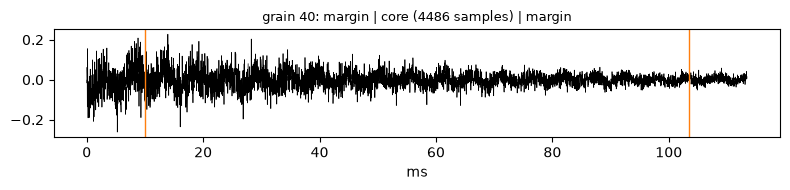

In [8]:
i = 40
w = pk.grain_window(i).astype(np.float32) / 32768.0
t = 1000 * np.arange(len(w)) / 48000
m = 1000 * pk.margin48 / 48000
fig, ax = plt.subplots(figsize=(8, 2))
ax.plot(t, w, lw=0.5, color="k")
for x in (m, t[-1] - m):
    ax.axvline(x, color="tab:orange", lw=1)
ax.set_xlabel("ms"); ax.set_title(f"grain {i}: margin | core ({pk.grain_len48} samples) | margin", fontsize=9)
fig.tight_layout()

## 5. Selection over the pack is the desktop instrument's selection

`corpus_builder/match.py` is the selection half of `granular.substitute`, written against the pack's arrays (and the
executable specification of the C++ matcher). With the same arrays, target latents, τ and seed, it must select the
same grains. The target is a held-out demo query encoded by the teacher.

In [9]:
queries = demo.encode_queries()
lat_q = queries["qt1"]["lat"]
cb_pack = granular.Codebook(name="demo", unit=1, raw=np.asarray(pk.raw), book=np.asarray(pk.emb), centre=np.asarray(pk.centre))
_, info = granular.substitute(lat_q, cb_pack, temperature=0.05, rng=np.random.default_rng(0))
res = match.Matcher.from_pack(pk).select(lat_q, temperature=0.05, rng=np.random.default_rng(0))
print(f"{len(res.picks)} input frames, identical selections: {res.picks == info.picks}")
print(f"hub share (selections on the 5 most-selected grains) {res.hubness:.3f}, distinct grains / selections {res.unique_frac:.3f}")

85 input frames, identical selections: True
hub share (selections on the 5 most-selected grains) 0.224, distinct grains / selections 0.682


## 6. The size of a corpus latent table

A 32-bit row is 64 × 4 = 256 bytes per grain. For the paper's corpora (`results/exp1/corpora.json`) that is the
table size the plugin reports on the board (`table_bytes` in the worker log of each run in `results/board/raw/`).

In [10]:
corpora = json.loads((demo.REPO / "results/exp1/corpora.json").read_text())["corpora"]
board = {(r.grains, r.table): r.header["table_bytes"] for r in load_runs()}
rows = []
for name, c in corpora.items():
    rows.append({"corpus": name, "grains": c["grains"], "minutes": c["minutes"], "files": c["files"],
                 "f32": 256 * c["grains"], "board": board.get((c["grains"], "f32"))})
report.table(rows, [("corpus", "Corpus"), ("files", "Files"), ("minutes", "Minutes", ".1f"), ("grains", "Grains", ","),
                    ("f32", "32-bit table (B)", ","), ("board", "Board log table_bytes", lambda v: f"{v:,}")])

| Corpus | Files | Minutes | Grains | 32-bit table (B) | Board log table_bytes |
|---|---|---|---|---|---|
| field | 9 | 18.6 | 12,018 | 3,076,608 | 3,076,608 |
| perc | 6 | 9.5 | 5,115 | 1,309,440 | 1,309,440 |
| text | 5 | 10.8 | 4,554 | 1,165,824 | — |
| tonal | 5 | 9.5 | 4,900 | 1,254,400 | — |

## Numbers of the paper this notebook reproduces

In [11]:
T0 = lats[0].shape[1]
frame_ms = 1000 * (len(y44s[0]) / T0) / granular.CODEC_SR
ok = report.checks([
    ("music2latent parameters (Introduction, Discussion)", "58 M", f"{n_total / 1e6:.1f} M", round(n_total / 1e6) == 58),
    ("latent dimension (Section 3)", "64", str(lats[0].shape[0]), lats[0].shape[0] == 64),
    ("one latent frame (Section 3)", "≈93 ms", f"{frame_ms:.1f} ms", round(frame_ms) == 93),
    ("pack audio (Section 3)", "16-bit", f"{8 * pk.audio.dtype.itemsize}-bit", pk.audio.dtype.itemsize == 2),
    ("field corpus, 32-bit table on the board (Figure 2 corpora)", "12,018 grains",
     f"{corpora['field']['grains']:,} grains, {256 * corpora['field']['grains']:,} B",
     corpora["field"]["grains"] == 12018 and board[(12018, "f32")] == 256 * 12018),
    ("selection over the pack = desktop instrument (Section 3)", "same code", f"{res.picks == info.picks}", res.picks == info.picks),
])
print("all equal:", ok)

| Paper element | Printed in the paper | Computed here | Equal |
|---|---|---|---|
| music2latent parameters (Introduction, Discussion) | 58 M | 58.2 M | ✓ |
| latent dimension (Section 3) | 64 | 64 | ✓ |
| one latent frame (Section 3) | ≈93 ms | 93.5 ms | ✓ |
| pack audio (Section 3) | 16-bit | 16-bit | ✓ |
| field corpus, 32-bit table on the board (Figure 2 corpora) | 12,018 grains | 12,018 grains, 3,076,608 B | ✓ |
| selection over the pack = desktop instrument (Section 3) | same code | True | ✓ |

all equal: True
